In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from banco import get_engine, executar

engine = get_engine()
pd.set_option("display.max_colwidth", 80)
pd.options.display.float_format = "{:,.2f}".format

def consulta(sql):
    return pd.read_sql(sql, engine)

def grafico_barras(df, rotulo, valor, titulo, eixo_x):
    d = df.sort_values(valor).copy()
    d[rotulo] = d[rotulo].astype(str).str.slice(0,45)
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(d) + 2))
    ax.barh(d[rotulo], d[valor].astype(float))
    ax.set_title(titulo)
    ax.set_xlabel(eixo_x)
    ax.ticklabel_format(axis="x", style="plain")
    plt.tight_layout()
    plt.show()

,nome_orgao_superior,qtd_viagens,custo_total
0,Ministério da Justiça e Segurança Pública,75742,"486,933,121.65"
1,Ministério da Defesa,61912,"156,070,304.49"
2,Ministério da Educação,65295,"111,291,349.34"
3,Ministério do Meio Ambiente e Mudança do Clima,19413,"49,697,710.16"
4,Ministério da Previdência Social,8190,"40,417,309.06"


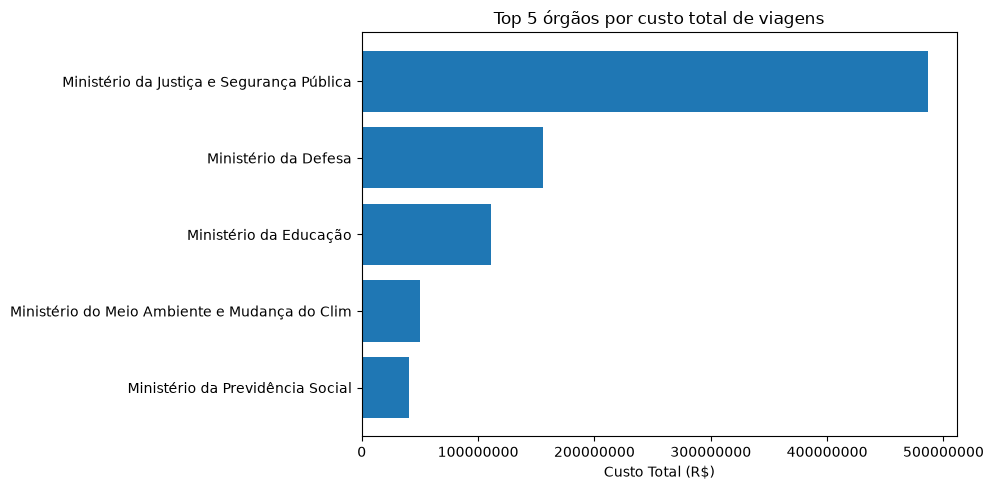

In [3]:
#Part 1 - Perguntas respondidas na Silver
# 1 - Quais os 5 órgãos com maior custo total?
SQL_Q1 = """
SELECT 
    nome_orgao_superior,
    count(*) as qtd_viagens,
    sum(valor_total) as custo_total
FROM 
silver_viagem
GROUP BY nome_orgao_superior
ORDER BY custo_total DESC
LIMIT 5
"""
q1 = consulta(SQL_Q1)
display(q1)
grafico_barras(q1, "nome_orgao_superior", "custo_total",
               "Top 5 órgãos por custo total de viagens", "Custo Total (R$)")
